In [1]:
import numpy as np
import matplotlib.pyplot as plt
import imodex_miri_postprocess_pipeline as imp #homemade pipeline
from scipy import ndimage
from scipy.optimize import curve_fit
from astropy.stats import sigma_clip
from astropy.io import fits
import glob
from scipy.optimize import minimize
#from collections import defaultdict
from scipy import ndimage
import math
import glob, os
import scipy.optimize as optimize

#ploting
import matplotlib.animation as animation
from matplotlib.animation import PillowWriter

In [2]:
path_save = '/home/cperrot/Work/projet/JWST/Target/GO/P6607/'

if not os.path.exists(path_save):
    os.makedirs(path_save)

pixscale = 0.110 # arcsec
lam = 7.7e-6    # lambda en m


aff  = 'cal'

path_1  = '/home/cperrot/Work/raw/JWST/Target/MAST/P6607/obs007/'
path_2  = '/home/cperrot/Work/raw/JWST/Target/MAST/P6607/obs017/'

cube_1 ,header_1   = imp.load_cube(path_1,aff)
cube_2 ,header_2   = imp.load_cube(path_2,aff)


cube_1 = imp.clean_image_nan(cube_1)
cube_2 = imp.clean_image_nan(cube_2)

dim = np.shape(cube_1)[-1]

Loading of 4 cubes.
Number of dimension : 2
Initial images size (px) : 256 / 256
New images size (px)     : 256 / 256
Loading of 4 cubes.
Number of dimension : 2
Initial images size (px) : 256 / 256
New images size (px)     : 256 / 256


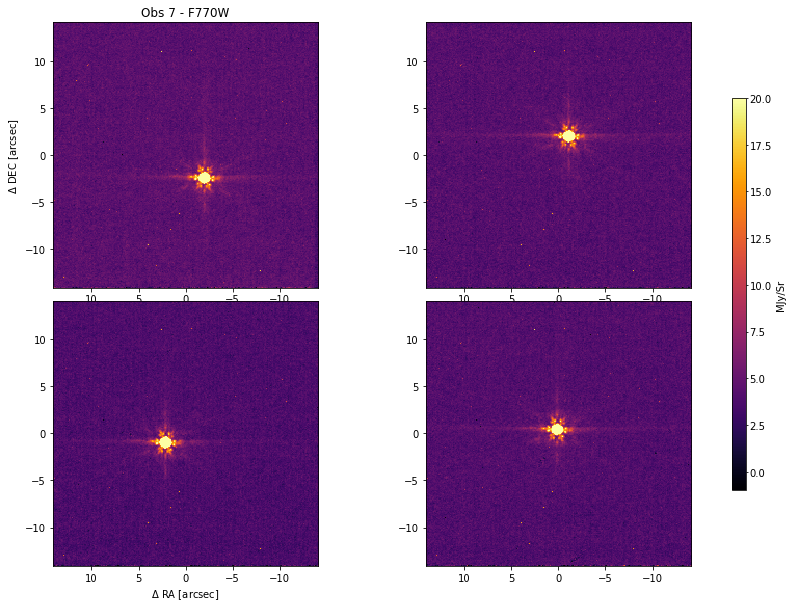

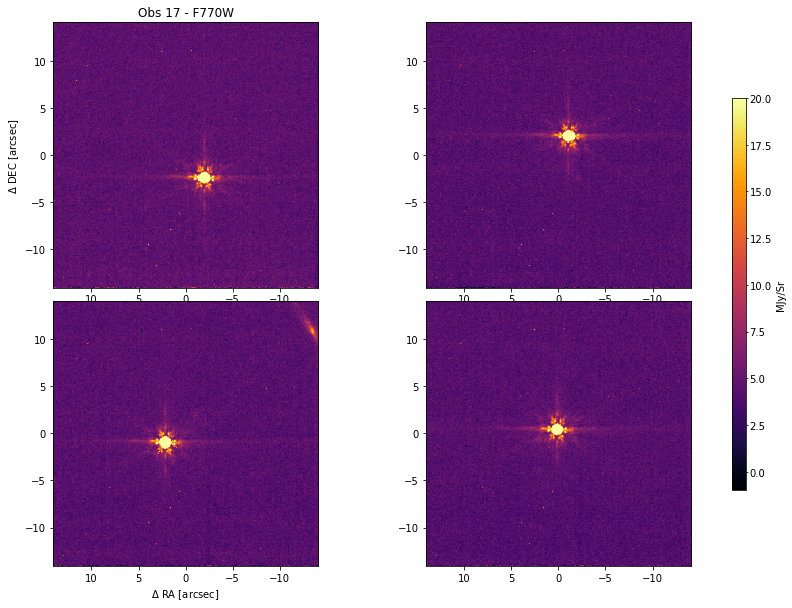

In [3]:
    vmin=-1
    vmax=20
    scale=[(dim/2.)*pixscale,-1*(dim/2.)*pixscale,-1*(dim/2.)*pixscale,(dim/2.)*pixscale]

    fig1,[[sub1,sub2],[sub3,sub4]] = plt.subplots(nrows=2,ncols=2,figsize=(10,10))
    plt.subplots_adjust(wspace=0.12, hspace=0.05, left=0.01, right=0.99)
    tmp1 = sub1.imshow(cube_1[0],origin='lower',cmap='inferno',interpolation='none',vmin=vmin,vmax=vmax,extent=scale)
    tmp2 = sub2.imshow(cube_1[1],origin='lower',cmap='inferno',interpolation='none',vmin=vmin,vmax=vmax,extent=scale)
    tmp3 = sub3.imshow(cube_1[2],origin='lower',cmap='inferno',interpolation='none',vmin=vmin,vmax=vmax,extent=scale)
    tmp4 = sub4.imshow(cube_1[3],origin='lower',cmap='inferno',interpolation='none',vmin=vmin,vmax=vmax,extent=scale)
    sub1.set_title('Obs 7 - F770W')
    sub1.set_ylabel(r'$\Delta$ DEC [arcsec]')
    sub3.set_xlabel(r'$\Delta$ RA [arcsec]')
    cax  = fig1.add_axes([1., 0.23, 0.02, 0.545])
    cbar = fig1.colorbar(tmp1, cax=cax, orientation='vertical')
    cbar.set_label('MJy/Sr',fontsize=10)
    cbar.ax.tick_params(length=2,pad=1,labelsize=10)
    # fig1.savefig(path_save+'HD181327_RDI_1140_roll1-2.pdf',format='pdf',bbox_inches='tight')
    plt.show()
    #    plt.close(fig1)
    
    
    
    fig2,[[sub1,sub2],[sub3,sub4]] = plt.subplots(nrows=2,ncols=2,figsize=(10,10))
    plt.subplots_adjust(wspace=0.12, hspace=0.05, left=0.01, right=0.99)
    tmp1 = sub1.imshow(cube_2[0],origin='lower',cmap='inferno',interpolation='none',vmin=vmin,vmax=vmax,extent=scale)
    tmp2 = sub2.imshow(cube_2[1],origin='lower',cmap='inferno',interpolation='none',vmin=vmin,vmax=vmax,extent=scale)
    tmp3 = sub3.imshow(cube_2[2],origin='lower',cmap='inferno',interpolation='none',vmin=vmin,vmax=vmax,extent=scale)
    tmp4 = sub4.imshow(cube_2[3],origin='lower',cmap='inferno',interpolation='none',vmin=vmin,vmax=vmax,extent=scale)
    sub1.set_title('Obs 17 - F770W')
    sub1.set_ylabel(r'$\Delta$ DEC [arcsec]')
    sub3.set_xlabel(r'$\Delta$ RA [arcsec]')
    cax  = fig2.add_axes([1., 0.23, 0.02, 0.545])
    cbar = fig2.colorbar(tmp1, cax=cax, orientation='vertical')
    cbar.set_label('MJy/Sr',fontsize=10)
    cbar.ax.tick_params(length=2,pad=1,labelsize=10)
    # fig2.savefig(path_save+'HD181327_RDI_1140_roll1-2.pdf',format='pdf',bbox_inches='tight')
    plt.show()
    # plt.close(fig2)

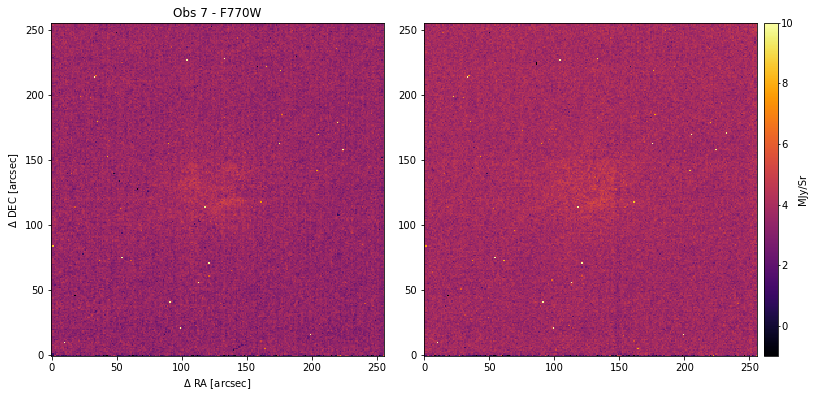

In [4]:
BKG_1 = np.min(cube_1,axis=0) #np.nanmedian(cube_1,axis=0)
BKG_2 = np.min(cube_2,axis=0) #np.nanmedian(cube_2,axis=0)

vmin=-1
vmax=10

nd=25
scale=[nd*pixscale,-1*nd*pixscale,-1*nd*pixscale,nd*pixscale]

fig1,[sub1,sub2] = plt.subplots(nrows=1,ncols=2,figsize=(10,8.5))
plt.subplots_adjust(wspace=0.12, hspace=0.05, left=0.01, right=0.99)
tmp1 = sub1.imshow(BKG_1,origin='lower',cmap='inferno',interpolation='none',vmin=vmin,vmax=vmax)
tmp2 = sub2.imshow(BKG_2,origin='lower',cmap='inferno',interpolation='none',vmin=vmin,vmax=vmax)
sub1.set_title('Obs 7 - F770W')
sub1.set_ylabel(r'$\Delta$ DEC [arcsec]')
sub1.set_xlabel(r'$\Delta$ RA [arcsec]')
cax  = fig1.add_axes([1., 0.23, 0.02, 0.545])
cbar = fig1.colorbar(tmp1, cax=cax, orientation='vertical')
cbar.set_label('MJy/Sr',fontsize=10)
cbar.ax.tick_params(length=2,pad=1,labelsize=10)
# fig1.savefig(path_save+'HD181327_RDI_1140_roll1-2.pdf',format='pdf',bbox_inches='tight')
plt.show()

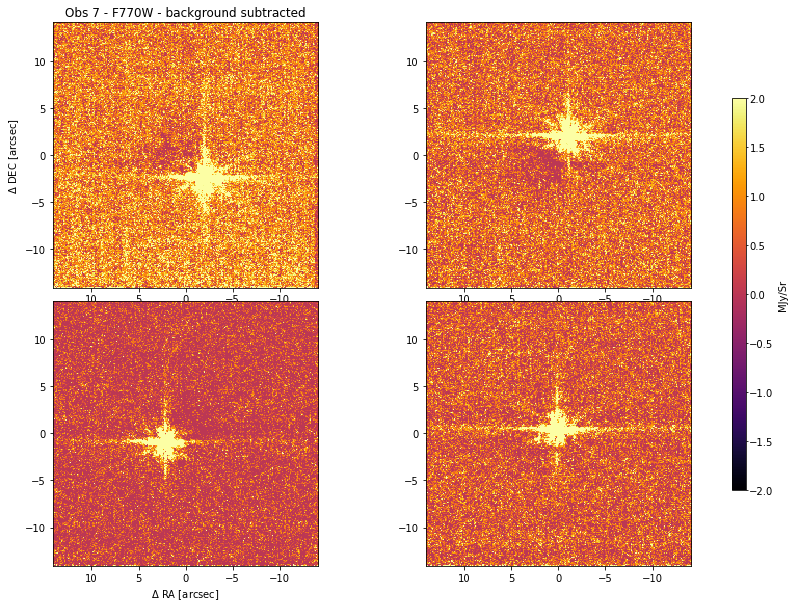

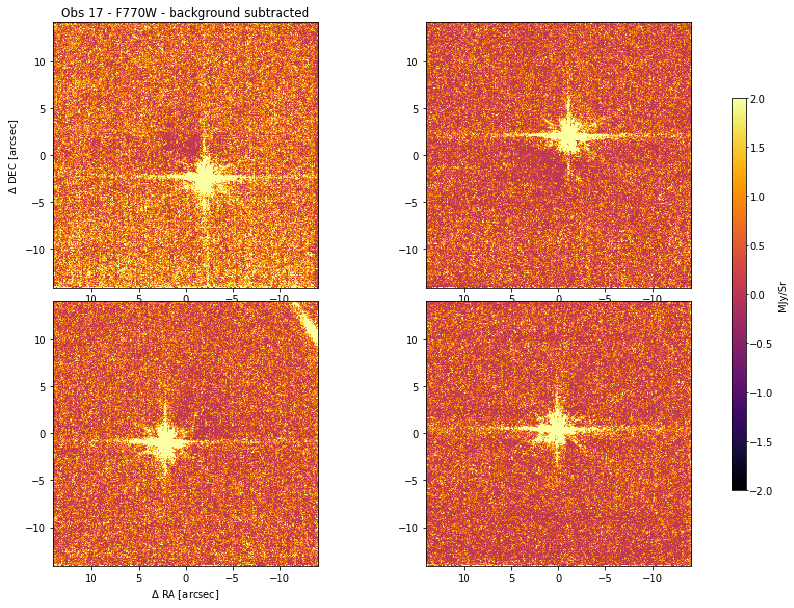

In [5]:
cube_1 -= BKG_1   
cube_2 -= BKG_2   

    
vmin=-2
vmax=2
scale=[(dim/2.)*pixscale,-1*(dim/2.)*pixscale,-1*(dim/2.)*pixscale,(dim/2.)*pixscale]

fig1,[[sub1,sub2],[sub3,sub4]] = plt.subplots(nrows=2,ncols=2,figsize=(10,10))
plt.subplots_adjust(wspace=0.12, hspace=0.05, left=0.01, right=0.99)
tmp1 = sub1.imshow(cube_1[0],origin='lower',cmap='inferno',interpolation='none',vmin=vmin,vmax=vmax,extent=scale)
tmp2 = sub2.imshow(cube_1[1],origin='lower',cmap='inferno',interpolation='none',vmin=vmin,vmax=vmax,extent=scale)
tmp3 = sub3.imshow(cube_1[2],origin='lower',cmap='inferno',interpolation='none',vmin=vmin,vmax=vmax,extent=scale)
tmp4 = sub4.imshow(cube_1[3],origin='lower',cmap='inferno',interpolation='none',vmin=vmin,vmax=vmax,extent=scale)
sub1.set_title('Obs 7 - F770W - background subtracted')
sub1.set_ylabel(r'$\Delta$ DEC [arcsec]')
sub3.set_xlabel(r'$\Delta$ RA [arcsec]')
cax  = fig1.add_axes([1., 0.23, 0.02, 0.545])
cbar = fig1.colorbar(tmp1, cax=cax, orientation='vertical')
cbar.set_label('MJy/Sr',fontsize=10)
cbar.ax.tick_params(length=2,pad=1,labelsize=10)
# fig1.savefig(path_save+'HD181327_RDI_1140_roll1-2.pdf',format='pdf',bbox_inches='tight')
plt.show()
#    plt.close(fig1)


vmin=-2
vmax=2
scale=[(dim/2.)*pixscale,-1*(dim/2.)*pixscale,-1*(dim/2.)*pixscale,(dim/2.)*pixscale]

fig1,[[sub1,sub2],[sub3,sub4]] = plt.subplots(nrows=2,ncols=2,figsize=(10,10))
plt.subplots_adjust(wspace=0.12, hspace=0.05, left=0.01, right=0.99)
tmp1 = sub1.imshow(cube_2[0],origin='lower',cmap='inferno',interpolation='none',vmin=vmin,vmax=vmax,extent=scale)
tmp2 = sub2.imshow(cube_2[1],origin='lower',cmap='inferno',interpolation='none',vmin=vmin,vmax=vmax,extent=scale)
tmp3 = sub3.imshow(cube_2[2],origin='lower',cmap='inferno',interpolation='none',vmin=vmin,vmax=vmax,extent=scale)
tmp4 = sub4.imshow(cube_2[3],origin='lower',cmap='inferno',interpolation='none',vmin=vmin,vmax=vmax,extent=scale)
sub1.set_title('Obs 17 - F770W - background subtracted')
sub1.set_ylabel(r'$\Delta$ DEC [arcsec]')
sub3.set_xlabel(r'$\Delta$ RA [arcsec]')
cax  = fig1.add_axes([1., 0.23, 0.02, 0.545])
cbar = fig1.colorbar(tmp1, cax=cax, orientation='vertical')
cbar.set_label('MJy/Sr',fontsize=10)
cbar.ax.tick_params(length=2,pad=1,labelsize=10)
# fig1.savefig(path_save+'HD181327_RDI_1140_roll1-2.pdf',format='pdf',bbox_inches='tight')
plt.show()
#    plt.close(fig1)

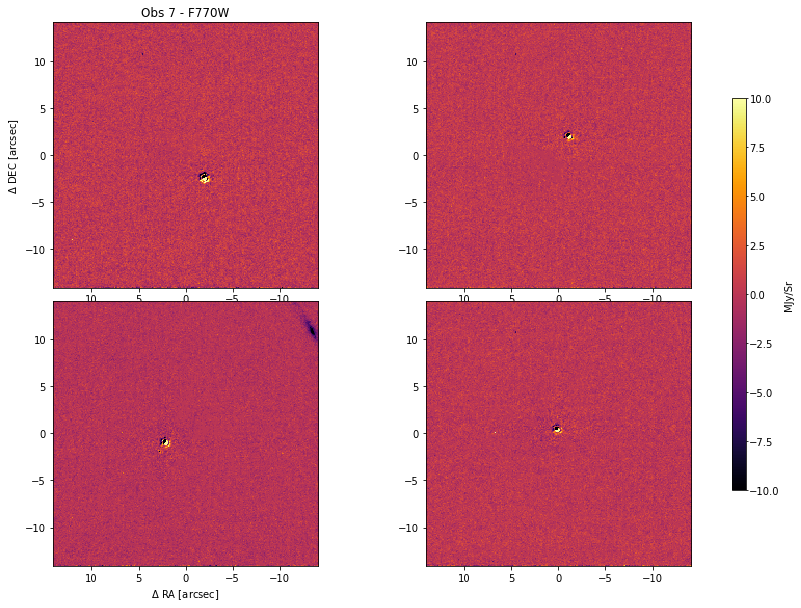

In [6]:
    vmin=-10
    vmax=10
    scale=[(dim/2.)*pixscale,-1*(dim/2.)*pixscale,-1*(dim/2.)*pixscale,(dim/2.)*pixscale]

    fig1,[[sub1,sub2],[sub3,sub4]] = plt.subplots(nrows=2,ncols=2,figsize=(10,10))
    plt.subplots_adjust(wspace=0.12, hspace=0.05, left=0.01, right=0.99)
    tmp1 = sub1.imshow(cube_1[0]-cube_2[0],origin='lower',cmap='inferno',interpolation='none',vmin=vmin,vmax=vmax,extent=scale)
    tmp2 = sub2.imshow(cube_1[1]-cube_2[1],origin='lower',cmap='inferno',interpolation='none',vmin=vmin,vmax=vmax,extent=scale)
    tmp3 = sub3.imshow(cube_1[2]-cube_2[2],origin='lower',cmap='inferno',interpolation='none',vmin=vmin,vmax=vmax,extent=scale)
    tmp4 = sub4.imshow(cube_1[3]-cube_2[3],origin='lower',cmap='inferno',interpolation='none',vmin=vmin,vmax=vmax,extent=scale)
    sub1.set_title('Obs 7 - F770W')
    sub1.set_ylabel(r'$\Delta$ DEC [arcsec]')
    sub3.set_xlabel(r'$\Delta$ RA [arcsec]')
    cax  = fig1.add_axes([1., 0.23, 0.02, 0.545])
    cbar = fig1.colorbar(tmp1, cax=cax, orientation='vertical')
    cbar.set_label('MJy/Sr',fontsize=10)
    cbar.ax.tick_params(length=2,pad=1,labelsize=10)
    # fig1.savefig(path_save+'HD181327_RDI_1140_roll1-2.pdf',format='pdf',bbox_inches='tight')
    plt.show()
    #    plt.close(fig1)

In [7]:
## opti by mathilde
def function_min_shift(P):
    return np.sum((img - P[0]*ndimage.shift(ref, [P[1], P[2]]))**2.)

img = cube_1[0]
ref = cube_2[0]
c_img_1 = np.where(img == img.max())
c_ref_1 = np.where(ref == ref.max())
cube_1[0] = ndimage.shift(cube_1[0], [dim/2-c_img_1[0],dim/2-c_img_1[1]])
cube_2[0] = ndimage.shift(cube_2[0], [dim/2-c_ref_1[0],dim/2-c_ref_1[1]])
P1 = optimize.fmin(function_min_shift, x0=(0.8, 0.0, 0.0))
print("rescale flux", P1[0])
print("Delta X", P1[1])
print("Delta Y", P1[2])


img = cube_1[1]
ref = cube_2[1]
c_img_2 = np.where(img == img.max())
c_ref_2 = np.where(ref == ref.max())
cube_1[1] = ndimage.shift(cube_1[1], [dim/2-c_img_2[0],dim/2-c_img_2[1]])
cube_2[1] = ndimage.shift(cube_2[1], [dim/2-c_ref_2[0],dim/2-c_ref_2[1]])
P2 = optimize.fmin(function_min_shift, x0=(0.8, 0.0, 0.0))
print("rescale flux", P2[0])
print("Delta X", P2[1])
print("Delta Y", P2[2])


img = cube_1[2]
ref = cube_2[2]
c_img_3 = np.where(img == img.max())
c_ref_3 = np.where(ref == ref.max())
cube_1[2] = ndimage.shift(cube_1[2], [dim/2-c_img_3[0],dim/2-c_img_3[1]])
cube_2[2] = ndimage.shift(cube_2[2], [dim/2-c_ref_3[0],dim/2-c_ref_3[1]])
P3 = optimize.fmin(function_min_shift, x0=(0.8, 0.0, 0.0))
print("rescale flux", P3[0])
print("Delta X", P3[1])
print("Delta Y", P3[2])


img = cube_1[3]
ref = cube_2[3]
c_img_4 = np.where(img == img.max())
c_ref_4 = np.where(ref == ref.max())
cube_1[3] = ndimage.shift(cube_1[3], [dim/2-c_img_4[0],dim/2-c_img_4[1]])
cube_2[3] = ndimage.shift(cube_2[3], [dim/2-c_ref_4[0],dim/2-c_ref_4[1]])
P4 = optimize.fmin(function_min_shift, x0=(0.8, 0.0, 0.0))
print("rescale flux", P4[0])
print("Delta X", P4[1])
print("Delta Y", P4[2])



cube_2[0] = ndimage.shift(cube_2[0], [P1[1], P1[2]])
cube_2[1] = ndimage.shift(cube_2[1], [P2[1], P2[2]])
cube_2[2] = ndimage.shift(cube_2[2], [P3[1], P3[2]])
cube_2[3] = ndimage.shift(cube_2[3], [P4[1], P4[2]])






Optimization terminated successfully.
         Current function value: 58087.390625
         Iterations: 175
         Function evaluations: 324
rescale flux 0.9885237419934829
Delta X -0.1977228019505862
Delta Y 0.08335928025062794
Optimization terminated successfully.
         Current function value: 38091.316406
         Iterations: 166
         Function evaluations: 318
rescale flux 0.9953180664177372
Delta X -0.0652372345260111
Delta Y 0.043599343949881825
Optimization terminated successfully.
         Current function value: 42201.210938
         Iterations: 148
         Function evaluations: 288
rescale flux 0.9843100679352828
Delta X 0.9162762942362153
Delta Y 0.084121258037433
Optimization terminated successfully.
         Current function value: 35052.464844
         Iterations: 146
         Function evaluations: 275
rescale flux 0.9937941784300917
Delta X -0.06748827083221211
Delta Y 0.042608909243525867


In [24]:

RDI_1 = (cube_1[0]-P1[0]*cube_2[0])/np.max(cube_1[0])
RDI_2 = (cube_1[1]-P2[0]*cube_2[1])/np.max(cube_1[1])
RDI_3 = (cube_1[2]-P3[0]*cube_2[2])/np.max(cube_1[2])
RDI_4 = (cube_1[3]-P4[0]*cube_2[3])/np.max(cube_1[3])



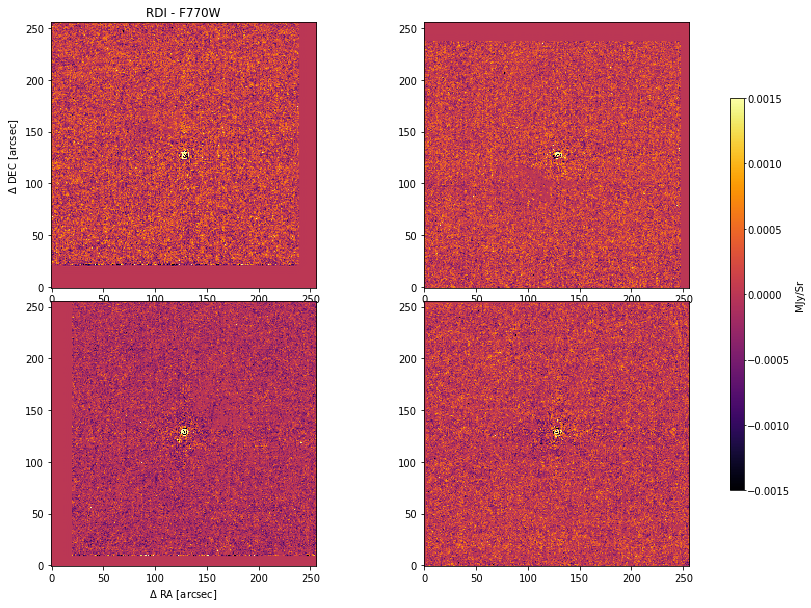

In [27]:



vmin=-1.5e-3
vmax=1.5e-3

scale=[dim/2*pixscale,-1*dim/2*pixscale,-1*dim/2*pixscale,dim/2*pixscale]

fig1,[[sub1,sub2],[sub3,sub4]] = plt.subplots(nrows=2,ncols=2,figsize=(10,10))
plt.subplots_adjust(wspace=0.12, hspace=0.05, left=0.01, right=0.99)
tmp1 = sub1.imshow(RDI_1,origin='lower',cmap='inferno',interpolation='none',vmin=vmin,vmax=vmax)
tmp2 = sub2.imshow(RDI_2,origin='lower',cmap='inferno',interpolation='none',vmin=vmin,vmax=vmax)
tmp3 = sub3.imshow(RDI_3,origin='lower',cmap='inferno',interpolation='none',vmin=vmin,vmax=vmax)
tmp4 = sub4.imshow(RDI_4,origin='lower',cmap='inferno',interpolation='none',vmin=vmin,vmax=vmax)
sub1.set_title('RDI - F770W')
sub1.set_ylabel(r'$\Delta$ DEC [arcsec]')
sub3.set_xlabel(r'$\Delta$ RA [arcsec]')
cax  = fig1.add_axes([1., 0.23, 0.02, 0.545])
cbar = fig1.colorbar(tmp1, cax=cax, orientation='vertical')
cbar.set_label('MJy/Sr',fontsize=10)
cbar.ax.tick_params(length=2,pad=1,labelsize=10)
# fig1.savefig(path_save+'HD181327_RDI_1140_roll1-2.pdf',format='pdf',bbox_inches='tight')
plt.show()


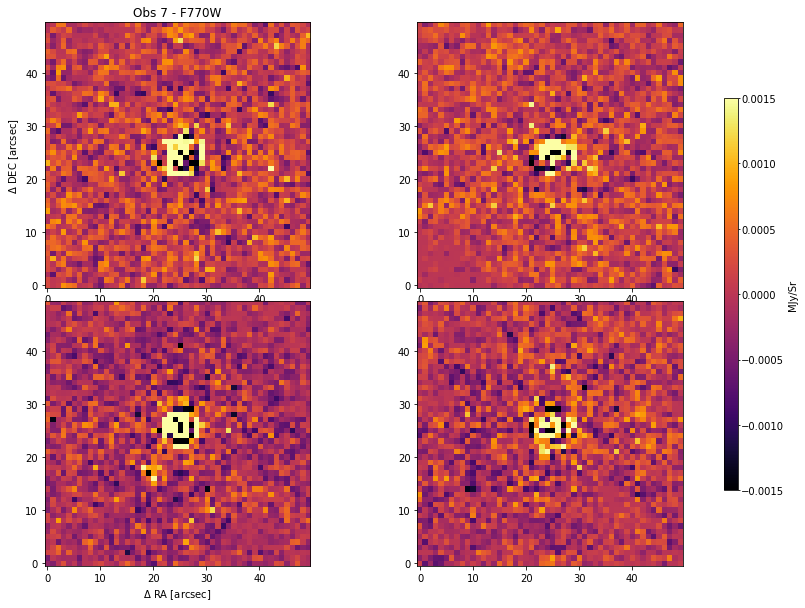

In [19]:
vmin=-1.5e-3
vmax=1.5e-3

nd=25
scale=[nd*pixscale,-1*nd*pixscale,-1*nd*pixscale,nd*pixscale]

fig1,[[sub1,sub2],[sub3,sub4]] = plt.subplots(nrows=2,ncols=2,figsize=(10,10))
plt.subplots_adjust(wspace=0.12, hspace=0.05, left=0.01, right=0.99)
tmp1 = sub1.imshow(RDI_1[dim//2-nd:dim//2+nd,dim//2-nd:dim//2+nd],origin='lower',cmap='inferno',interpolation='none',vmin=vmin,vmax=vmax)
tmp2 = sub2.imshow(RDI_2[dim//2-nd:dim//2+nd,dim//2-nd:dim//2+nd],origin='lower',cmap='inferno',interpolation='none',vmin=vmin,vmax=vmax)
tmp3 = sub3.imshow(RDI_3[dim//2-nd:dim//2+nd,dim//2-nd:dim//2+nd],origin='lower',cmap='inferno',interpolation='none',vmin=vmin,vmax=vmax)
tmp4 = sub4.imshow(RDI_4[dim//2-nd:dim//2+nd,dim//2-nd:dim//2+nd],origin='lower',cmap='inferno',interpolation='none',vmin=vmin,vmax=vmax)
sub1.set_title('Obs 7 - F770W')
sub1.set_ylabel(r'$\Delta$ DEC [arcsec]')
sub3.set_xlabel(r'$\Delta$ RA [arcsec]')
cax  = fig1.add_axes([1., 0.23, 0.02, 0.545])
cbar = fig1.colorbar(tmp1, cax=cax, orientation='vertical')
cbar.set_label('MJy/Sr',fontsize=10)
cbar.ax.tick_params(length=2,pad=1,labelsize=10)
# fig1.savefig(path_save+'HD181327_RDI_1140_roll1-2.pdf',format='pdf',bbox_inches='tight')
plt.show()

In [30]:
mask = np.concatenate([np.arange(-127.5,0.5,1)*(-1),np.arange(0.5,128.5,1)])
mask = np.sqrt(mask**2+mask[:,np.newaxis]**2)

cst_std_1 = []
cst_med_1 = []
cst_moy_1 = []
copy_RDI = RDI_1.copy() #copie du cube 1
copy_RDI[np.where(copy_RDI <=0 )] = math.nan      #valeur neg en NaN pour pas affecterla moyenne/med/std
for i in np.arange(2,181,2):
    cst_med_1.append(np.nanmedian((copy_RDI[(mask>i-2) & (mask<=i)])))
    cst_moy_1.append(np.nanmean((copy_RDI[(mask>i-2) & (mask<=i)])))
    cst_std_1.append(np.nanstd((copy_RDI[(mask>i-2) & (mask<=i)])))
  
cst_std_2 = []
cst_med_2 = []
cst_moy_2 = []
copy_RDI = RDI_2.copy() #copie du cube 1
copy_RDI[np.where(copy_RDI <=0 )] = math.nan      #valeur neg en NaN pour pas affecterla moyenne/med/std
for i in np.arange(2,181,2):
    cst_med_2.append(np.nanmedian((copy_RDI[(mask>i-2) & (mask<=i)])))
    cst_moy_2.append(np.nanmean((copy_RDI[(mask>i-2) & (mask<=i)])))
    cst_std_2.append(np.nanstd((copy_RDI[(mask>i-2) & (mask<=i)])))
  

cst_std_3 = []
cst_med_3 = []
cst_moy_3 = []
copy_RDI = RDI_3.copy() #copie du cube 1
copy_RDI[np.where(copy_RDI <=0 )] = math.nan      #valeur neg en NaN pour pas affecterla moyenne/med/std
for i in np.arange(2,181,2):
    cst_med_3.append(np.nanmedian((copy_RDI[(mask>i-2) & (mask<=i)])))
    cst_moy_3.append(np.nanmean((copy_RDI[(mask>i-2) & (mask<=i)])))
    cst_std_3.append(np.nanstd((copy_RDI[(mask>i-2) & (mask<=i)])))
  

cst_std_4 = []
cst_med_4 = []
cst_moy_4 = []
copy_RDI = RDI_4.copy() #copie du cube 1
copy_RDI[np.where(copy_RDI <=0 )] = math.nan      #valeur neg en NaN pour pas affecterla moyenne/med/std
for i in np.arange(2,181,2):
    cst_med_4.append(np.nanmedian((copy_RDI[(mask>i-2) & (mask<=i)])))
    cst_moy_4.append(np.nanmean((copy_RDI[(mask>i-2) & (mask<=i)])))
    cst_std_4.append(np.nanstd((copy_RDI[(mask>i-2) & (mask<=i)])))


cst_std = []
cst_med = []
cst_moy = []
copy_RDI = (RDI_1.copy()+RDI_2.copy()+RDI_3.copy()+RDI_4.copy())/4. #copie du cube 1
copy_RDI[np.where(copy_RDI <=0 )] = math.nan      #valeur neg en NaN pour pas affecterla moyenne/med/std
for i in np.arange(2,181,2):
    cst_med.append(np.nanmedian((copy_RDI[(mask>i-2) & (mask<=i)])))
    cst_moy.append(np.nanmean((copy_RDI[(mask>i-2) & (mask<=i)])))
    cst_std.append(np.nanstd((copy_RDI[(mask>i-2) & (mask<=i)])))

    
    
    
    

array([ 0.11,  0.33,  0.55,  0.77,  0.99,  1.21,  1.43,  1.65,  1.87,
        2.09,  2.31,  2.53,  2.75,  2.97,  3.19,  3.41,  3.63,  3.85,
        4.07,  4.29,  4.51,  4.73,  4.95,  5.17,  5.39,  5.61,  5.83,
        6.05,  6.27,  6.49,  6.71,  6.93,  7.15,  7.37,  7.59,  7.81,
        8.03,  8.25,  8.47,  8.69,  8.91,  9.13,  9.35,  9.57,  9.79,
       10.01, 10.23, 10.45, 10.67, 10.89, 11.11, 11.33, 11.55, 11.77,
       11.99, 12.21, 12.43, 12.65, 12.87, 13.09, 13.31, 13.53, 13.75,
       13.97, 14.19, 14.41, 14.63, 14.85, 15.07, 15.29, 15.51, 15.73,
       15.95, 16.17, 16.39, 16.61, 16.83, 17.05, 17.27, 17.49, 17.71,
       17.93, 18.15, 18.37, 18.59, 18.81, 19.03, 19.25, 19.47, 19.69])

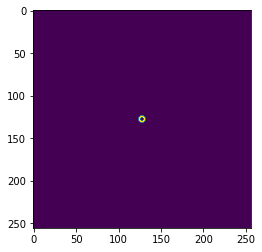

In [45]:
plt.imshow((mask>4-2) & (mask<=4))
np.arange(2,181,2)
np.arange(1,181,2)*pixscale

/tmp/ipykernel_20115/976099392.py:15: UserWarning: Attempted to set non-positive left xlim on a log-scaled axis.
Invalid limit will be ignored.
  plt.xlim(0,100)


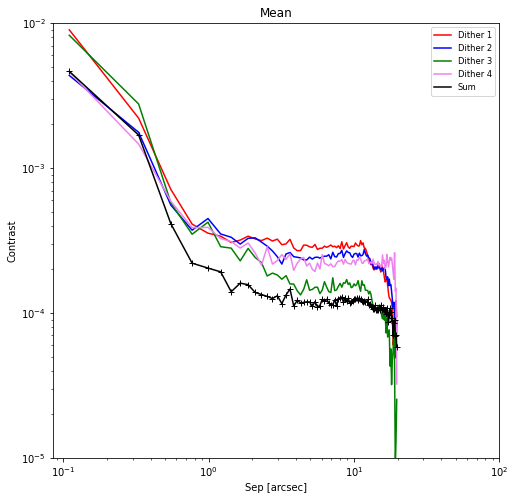

/tmp/ipykernel_20115/976099392.py:31: UserWarning: Attempted to set non-positive left xlim on a log-scaled axis.
Invalid limit will be ignored.
  plt.xlim(0,100)


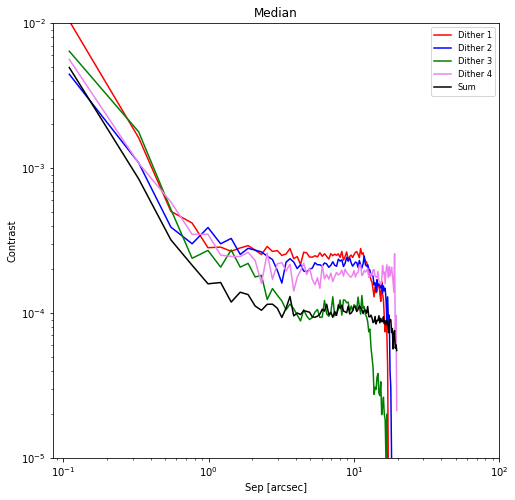

/tmp/ipykernel_20115/976099392.py:47: UserWarning: Attempted to set non-positive left xlim on a log-scaled axis.
Invalid limit will be ignored.
  plt.xlim(0,100)


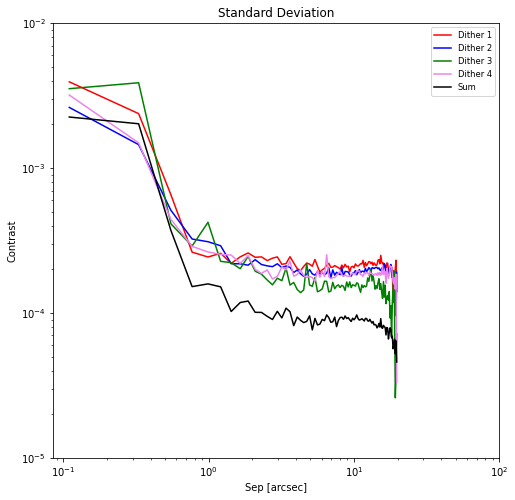

In [38]:
plt.figure(figsize=(8,8))
plt.plot(np.arange(1,181,2)*pixscale,cst_moy_1,color='red',label='Dither 1')
plt.plot(np.arange(1,181,2)*pixscale,cst_moy_2,color='blue',label='Dither 2')
plt.plot(np.arange(1,181,2)*pixscale,cst_moy_3,color='green',label='Dither 3')
plt.plot(np.arange(1,181,2)*pixscale,cst_moy_4,color='violet',label='Dither 4')
plt.plot(np.arange(1,181,2)*pixscale,cst_moy,color='black',label='Sum')
plt.plot(np.arange(1,181,2)*pixscale,cst_moy,'+',color='black')
plt.title('Mean')
plt.yscale('log')
plt.xscale('log')
plt.xlabel('Sep [arcsec]')
plt.ylabel('Contrast')
plt.legend(loc='upper right',fontsize='small')
plt.ylim(1e-5,1e-2)
plt.xlim(0,100)
plt.show()

plt.figure(figsize=(8,8))
plt.plot(np.arange(1,181,2)*pixscale,cst_med_1,color='red',label='Dither 1')
plt.plot(np.arange(1,181,2)*pixscale,cst_med_2,color='blue',label='Dither 2')
plt.plot(np.arange(1,181,2)*pixscale,cst_med_3,color='green',label='Dither 3')
plt.plot(np.arange(1,181,2)*pixscale,cst_med_4,color='violet',label='Dither 4')
plt.plot(np.arange(1,181,2)*pixscale,cst_med,color='black',label='Sum')
plt.title('Median')
plt.yscale('log')
plt.xscale('log')
plt.xlabel('Sep [arcsec]')
plt.ylabel('Contrast')
plt.legend(loc='upper right',fontsize='small')
plt.ylim(1e-5,1e-2)
plt.xlim(0,100)
plt.show()

plt.figure(figsize=(8,8))
plt.plot(np.arange(1,181,2)*pixscale,cst_std_1,color='red',label='Dither 1')
plt.plot(np.arange(1,181,2)*pixscale,cst_std_2,color='blue',label='Dither 2')
plt.plot(np.arange(1,181,2)*pixscale,cst_std_3,color='green',label='Dither 3')
plt.plot(np.arange(1,181,2)*pixscale,cst_std_4,color='violet',label='Dither 4')
plt.plot(np.arange(1,181,2)*pixscale,cst_std,color='black',label='Sum')
plt.title('Standard Deviation')
plt.yscale('log')
plt.xscale('log')
plt.xlabel('Sep [arcsec]')
plt.ylabel('Contrast')
plt.legend(loc='upper right',fontsize='small')
plt.ylim(1e-5,1e-2)
plt.xlim(0,100)
plt.show()
